# Asymptote Fits for Graph Invariants

Load the precomputed invariant measurements across checkpoints and fit finite-size correction curves to estimate their limiting behavior.


In [1]:
import json
import math
import pathlib
from dataclasses import dataclass
from typing import Callable, Iterable

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from refig import refig

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "Roboto"
plt.rcParams["figure.dpi"] = 150

DATA_PATH = pathlib.Path("invariants_per_graph.json")
if not DATA_PATH.exists():
    DATA_PATH = pathlib.Path("../notebooks/invariants_per_graph.json")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not locate invariants_per_graph.json relative to this notebook."
    )

FIGURE_DIR = pathlib.Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
with open(DATA_PATH) as f:
    invariants_per_graph = json.load(f)


def checkpoint_to_edits(label: str) -> int:
    clean = label.strip().lower()
    if clean.endswith("k"):
        return int(clean[:-1]) * 1000
    return int(clean)


reference_invariant = next(iter(invariants_per_graph))
checkpoint_labels = sorted(
    invariants_per_graph[reference_invariant].keys(),
    key=checkpoint_to_edits,
)
checkpoint_edits = np.array(
    [checkpoint_to_edits(label) for label in checkpoint_labels],
    dtype=float,
)
checkpoint_lookup = dict(zip(checkpoint_labels, checkpoint_edits))
unique_edits = np.unique(checkpoint_edits)
positive_gaps = np.diff(unique_edits)
positive_gaps = positive_gaps[positive_gaps > 0]
DEFAULT_SHIFT = float(positive_gaps.min() / 2) if positive_gaps.size else 1.0

print(
    f"Loaded {len(invariants_per_graph)} invariants across "
    f"{len(checkpoint_labels)} checkpoints."
)
print(f"Checkpoint shift (delta) for feature transforms: {DEFAULT_SHIFT:.0f} edits")


Loaded 11 invariants across 10 checkpoints.
Checkpoint shift (delta) for feature transforms: 2500 edits


In [3]:

@dataclass
class ModelSpec:
    name: str
    feature_fns: tuple[Callable[[np.ndarray], np.ndarray], ...]
    description: str
    has_limit: bool


def make_inv_power(power: float) -> Callable[[np.ndarray], np.ndarray]:
    def transform(n: np.ndarray) -> np.ndarray:
        return n.astype(float) ** (-power)

    return transform


def make_exp_decay(tau: float) -> Callable[[np.ndarray], np.ndarray]:
    def transform(n: np.ndarray) -> np.ndarray:
        return np.exp(-(n.astype(float)) / tau)

    return transform


def make_monomial(power: float) -> Callable[[np.ndarray], np.ndarray]:
    def transform(n: np.ndarray) -> np.ndarray:
        return n.astype(float) ** power

    return transform


MODEL_SPECS: list[ModelSpec] = [
    ModelSpec(
        name="Constant",
        feature_fns=tuple(),
        description="y = L",
        has_limit=True,
    ),
    ModelSpec(
        name="Poly-Linear",
        feature_fns=(make_monomial(1.0),),
        description="y = a + b (n+delta)",
        has_limit=False,
    ),
    ModelSpec(
        name="Inverse-Linear",
        feature_fns=(make_inv_power(1.0),),
        description="y = L + a/(n+delta)",
        has_limit=True,
    ),
    ModelSpec(
        name="Inverse-Square",
        feature_fns=(make_inv_power(2.0),),
        description="y = L + a/(n+delta)^2",
        has_limit=True,
    ),
    ModelSpec(
        name="Inverse-Cubic",
        feature_fns=(make_inv_power(3.0),),
        description="y = L + a/(n+delta)^3",
        has_limit=True,
    ),
    ModelSpec(
        name="Inverse-Quartic",
        feature_fns=(make_inv_power(4.0),),
        description="y = L + a/(n+delta)^4",
        has_limit=True,
    ),
]

exp_taus = (5000.0, 10000.0, 20000.0)
for tau in exp_taus:
    MODEL_SPECS.append(
        ModelSpec(
            name=f"Exp-{int(tau / 1000)}k",
            feature_fns=(make_exp_decay(tau),),
            description=f"y = L + a * exp(-(n+delta)/{int(tau)})",
            has_limit=True,
        )
    )

SPEC_PRIORITY = {
    "Constant": 0,
    "Poly-Linear": 1,
    "Inverse-Linear": 2,
    "Inverse-Square": 3,
    "Inverse-Cubic": 4,
    "Inverse-Quartic": 5,
    "Exp-5k": 6,
    "Exp-10k": 7,
    "Exp-20k": 8,
}
BIC_TOLERANCE = 1.5
LIMIT_PREFERENCE_DELTA = 2.5


def build_design_matrix(
    x_edits: np.ndarray, spec: ModelSpec, shift: float = DEFAULT_SHIFT
) -> np.ndarray:
    n_eff = x_edits.astype(float) + shift
    columns = [np.ones_like(n_eff)]
    for fn in spec.feature_fns:
        columns.append(fn(n_eff))
    return np.column_stack(columns)


def is_monotonic(values: np.ndarray, tol: float = 1e-9) -> bool:
    diffs = np.diff(values)
    return bool((diffs >= -tol).all()) or bool((diffs <= tol).all())


def fit_model(
    x_edits: np.ndarray,
    values: np.ndarray,
    spec: ModelSpec,
    shift: float = DEFAULT_SHIFT,
) -> dict:
    X = build_design_matrix(x_edits, spec, shift)
    params, _, _, _ = np.linalg.lstsq(X, values, rcond=None)
    fitted = X @ params
    residuals = values - fitted
    sse = float(np.sum(residuals**2))
    n_obs = len(values)
    n_params = X.shape[1]
    dof = max(n_obs - n_params, 1)
    mse = sse / dof
    bic = n_obs * math.log(mse + 1e-12) + n_params * math.log(n_obs)
    aic = n_obs * math.log((sse / n_obs) + 1e-12) + 2 * n_params
    valid = is_monotonic(fitted)
    return {
        "spec": spec,
        "params": params,
        "fitted": fitted,
        "residuals": residuals,
        "sse": sse,
        "bic": bic,
        "aic": aic,
        "shift": shift,
        "n_obs": n_obs,
        "valid": valid,
    }


def select_best_fit(candidate_fits: list[dict]) -> dict:
    ordered = sorted(
        candidate_fits,
        key=lambda item: (
            item["bic"],
            SPEC_PRIORITY.get(item["spec"].name, 99),
        ),
    )
    best = ordered[0]
    if best["spec"].name.startswith("Exp-"):
        alternatives = [
            fit
            for fit in ordered
            if not fit["spec"].name.startswith("Exp-")
            and fit["bic"] - best["bic"] <= BIC_TOLERANCE
        ]
        if alternatives:
            best = alternatives[0]
    if not best["spec"].has_limit:
        limit_candidates = [
            fit
            for fit in ordered
            if fit["spec"].has_limit
            and fit["bic"] - best["bic"] <= LIMIT_PREFERENCE_DELTA
        ]
        if limit_candidates:
            best = limit_candidates[0]
    return best


def predict_from_fit(x_edits: np.ndarray, fit: dict) -> np.ndarray:
    X = build_design_matrix(x_edits, fit["spec"], fit["shift"])
    return X @ fit["params"]


def get_limit_value(fit: dict) -> float | None:
    if not fit["spec"].has_limit:
        return None
    return float(fit["params"][0])


def estimate_progress_edit(
    result: dict,
    fraction: float,
    limit_value: float | None,
    max_multiplier: float = 10.0,
    points: int = 2000,
) -> float | None:
    if limit_value is None:
        return None
    start_value = result["y"][0]
    if math.isclose(start_value, limit_value, rel_tol=1e-9, abs_tol=1e-9):
        return None
    target_value = start_value + (limit_value - start_value) * fraction
    direction = 1 if limit_value > start_value else -1
    x_data = result["x"]
    x_min = float(x_data.min())
    x_max = float(x_data.max())
    current_max = x_max
    for _ in range(12):
        x_grid = np.linspace(x_min, current_max, points)
        y_grid = predict_from_fit(x_grid, result["best_fit"])
        if direction > 0:
            mask = y_grid >= target_value - 1e-9
        else:
            mask = y_grid <= target_value + 1e-9
        if np.any(mask):
            idx = int(np.where(mask)[0][0])
            return float(x_grid[idx])
        current_max *= max_multiplier
    return None


PROGRESS_LEVELS = (0.50, 0.80, 0.90, 0.95, 0.99)
PLOT_EXCLUDE = {"density"}




In [4]:
fit_results = []
skipped = []

for invariant_name, values_by_checkpoint in invariants_per_graph.items():
    xs = []
    ys = []
    for label in checkpoint_labels:
        value = values_by_checkpoint.get(label)
        if value is None:
            continue
        xs.append(checkpoint_lookup[label])
        ys.append(value)
    x_arr = np.array(xs, dtype=float)
    y_arr = np.array(ys, dtype=float)
    if x_arr.size < 3:
        skipped.append(invariant_name)
        continue
    candidate_fits = []
    for spec in MODEL_SPECS:
        fit = fit_model(x_arr, y_arr, spec, DEFAULT_SHIFT)
        if not fit["valid"]:
            continue
        candidate_fits.append(fit)
    if not candidate_fits:
        skipped.append(invariant_name)
        continue
    best_fit = select_best_fit(candidate_fits)
    fit_results.append(
        {
            "invariant": invariant_name,
            "x": x_arr,
            "y": y_arr,
            "best_fit": best_fit,
            "candidate_fits": candidate_fits,
        }
    )

print(f"Fitted asymptotes for {len(fit_results)} invariants.")
if skipped:
    print(
        "Skipped due to insufficient data or monotonic fits:",
        ", ".join(skipped),
    )


Fitted asymptotes for 11 invariants.


In [18]:
def format_progress(value: float | None, italic: bool = False) -> str:
    if value is None or math.isinf(value) or math.isnan(value):
        return "—"
    text = f"{value:,.0f}"
    return f"_{text}_" if italic else text


summary_lines = [
    "| Invariant | Best model | Asymptote (L) | 50% edits | 80% edits | 90% edits | 95% edits | 99% edits |",
    "| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |",
]

for result in sorted(fit_results, key=lambda item: item["invariant"]):
    best = result["best_fit"]
    limit_value = get_limit_value(best)
    asymptote_text = f"{limit_value:.6g}" if limit_value is not None else "—"
    milestones = []
    last_observed = result["x"].max()
    for level in PROGRESS_LEVELS:
        edit_value = estimate_progress_edit(result, level, limit_value)
        italic = (
            edit_value is not None
            and edit_value <= last_observed + 1e-9
        )
        milestones.append(format_progress(edit_value, italic=italic))

    summary_lines.append(
        "| {inv} | {model} | {asym} | {p50} | {p80} | {p90} | {p95} | {p99} |".format(
            inv=result["invariant"],
            model=best["spec"].name,
            asym=asymptote_text,
            p50=milestones[0],
            p80=milestones[1],
            p90=milestones[2],
            p95=milestones[3],
            p99=milestones[4],
        )
    )

display(Markdown("\n".join(summary_lines)))

# Generate an SVG figure of the table:
fig = plt.figure(figsize=(12, len(summary_lines) * 0.4))
ax = fig.add_subplot(1, 1, 1)
ax.axis("off")
table_data = [line.strip().split("|")[1:-1] for line in summary_lines]
table = ax.table(
    cellText=table_data[1:],
    colLabels=table_data[0],
    cellLoc="center",
    loc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)
fig.tight_layout()
figure_path = FIGURE_DIR / "invariant_asymptote_summary.svg"
refig.savefig(str(figure_path))

| Invariant | Best model | Asymptote (L) | 50% edits | 80% edits | 90% edits | 95% edits | 99% edits |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| average_clustering | Exp-20k | 0.0214889 | _13,462_ | _31,786_ | 45,698 | 59,655 | 91,846 |
| average_degree | Poly-Linear | — | — | — | — | — | — |
| degree_assortativity | Poly-Linear | — | — | — | — | — | — |
| degree_entropy | Poly-Linear | — | — | — | — | — | — |
| density | Poly-Linear | — | — | — | — | — | — |
| diameter | Exp-20k | 5.9147 | _15,443_ | _33,767_ | 47,724 | 61,681 | 93,872 |
| giant_component_fraction | Poly-Linear | — | — | — | — | — | — |
| molloy_reed_index | Exp-20k | 63.528 | _14,295_ | _32,641_ | 46,598 | 60,555 | 92,746 |
| reciprocity | Poly-Linear | — | — | — | — | — | — |
| transitivity | Exp-20k | 0.0232872 | _13,957_ | _32,281_ | 46,148 | 60,105 | 92,296 |
| triangle_count | Poly-Linear | — | — | — | — | — | — |

SaveResult(latest_path=PosixPath('figures/latest/invariant_asymptote_summary.svg'), history_path=PosixPath('figures/history/invariant_asymptote_summary/_20251109T203150_45162ad.svg'), metadata={'figure': 'invariant_asymptote_summary.svg', 'created_at': '2025-11-09T20:31:50.392671+00:00', 'source': '/private/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_1766/1800620675.py', 'cell_number': 18, 'git_commit': '45162adcea36de35018b8c572505adc3fe96f0f2', 'refig_version': '0.1.0'})

/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_1766/1104992716.py:84: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_1766/1104992716.py:84: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_1766/1104992716.py:84: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_1766/1104992716.py:84: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([
/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_1766/1104

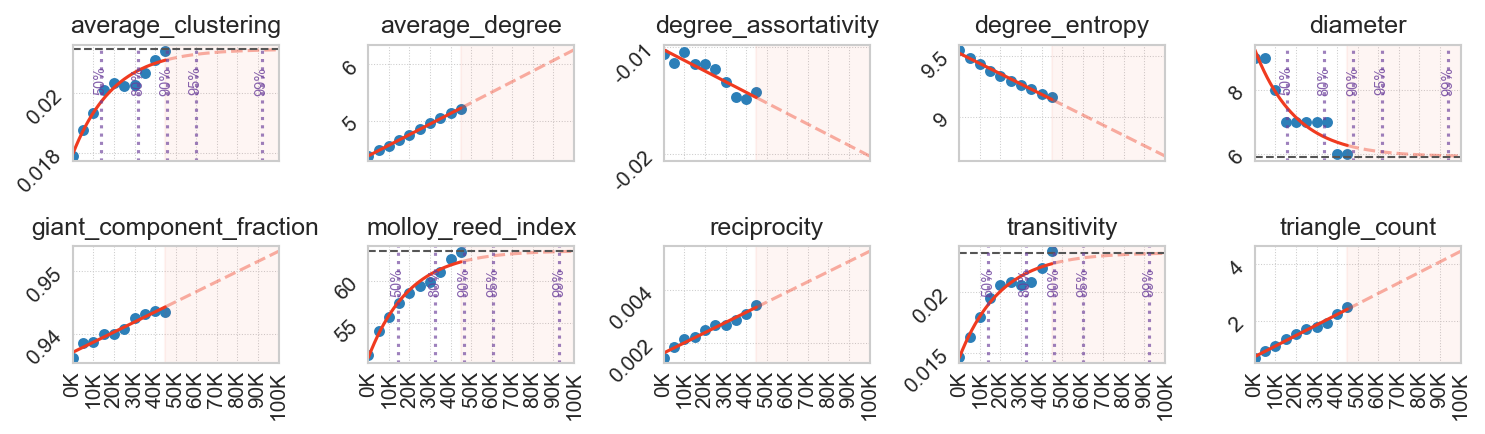

In [15]:

def chunked(iterable: Iterable, size: int) -> list[list]:
    chunk = []
    for item in iterable:
        chunk.append(item)
        if len(chunk) == size:
            yield chunk
            chunk = []
    if chunk:
        yield chunk


with plt.style.context("seaborn-v0_8-whitegrid"):
    sorted_results = sorted(fit_results, key=lambda item: item["invariant"])
    plot_results = [
        result
        for result in sorted_results
        if result["invariant"] not in PLOT_EXCLUDE
    ]
    group_size = 10
    future_limit = 100_000.0
    tick_min = 0
    tick_max = 100_000.0
    tick_inc = 10000.0
    xtick_positions = np.arange(tick_min, tick_max + 1e-9, tick_inc)
    xtick_labels = [f"{int(pos/1000)}K" for pos in xtick_positions]
    milestone_color = "#6a3d9a"
    for group_idx, group in enumerate(chunked(plot_results, group_size), start=1):
        fig, axes = plt.subplots(2, 5, figsize=(10, 3), sharex=True)
        axes = axes.flatten()
        for ax, result in zip(axes, group):
            x = result["x"]
            y = result["y"]
            best = result["best_fit"]
            limit_value = get_limit_value(best)
            last_observed = x.max()
            x_grid = np.linspace(x.min(), max(future_limit, last_observed), 600)
            y_grid = predict_from_fit(x_grid, best)

            ax.scatter(x, y, color="#2c7fb8", s=18)

            past_mask = x_grid <= last_observed
            ax.plot(
                x_grid[past_mask],
                y_grid[past_mask],
                color="#f03b20",
            )
            if np.any(~past_mask):
                ax.plot(
                    x_grid[~past_mask],
                    y_grid[~past_mask],
                    color="#f03b20",
                    alpha=0.4,
                    linestyle="--",
                )

            if limit_value is not None:
                ax.axhline(
                    limit_value,
                    color="#555555",
                    linestyle="--",
                    linewidth=1,
                )

            milestone_values = []
            for level in PROGRESS_LEVELS:
                edit_value = estimate_progress_edit(result, level, limit_value)
                if edit_value is None or edit_value > future_limit:
                    continue
                milestone_values.append((level, edit_value))

            if future_limit > last_observed:
                ax.axvspan(
                    last_observed,
                    future_limit,
                    color="#f03b20",
                    alpha=0.05,
                )

            ax.set_title(result["invariant"])
            # ax.set_ylabel("Invariant value")
            ax.set_xlim(0, future_limit)
            ax.set_xticks(xtick_positions)
            ax.set_xticklabels(xtick_labels, rotation=90)
            ax.set_yticklabels([
                f"{ytick:.2g}" for ytick in ax.get_yticks()
            ], rotation=45)


            ymin, ymax = ax.get_ylim()
            for level, edit_value in milestone_values:
                ax.axvline(
                    edit_value,
                    color=milestone_color,
                    linestyle=":",
                    linewidth=1.5,
                    alpha=0.65,
                )
                ax.annotate(
                    f"{int(level * 100)}%",
                    xy=(edit_value, ymax),
                    xytext=(0, -10),
                    textcoords="offset points",
                    rotation=90,
                    ha="center",
                    va="top",
                    fontsize=7,
                    color=milestone_color,
                    alpha=0.8,
                )

        for ax in axes:
            ax.grid(True, linestyle=":", linewidth=0.5)

        for ax in axes[len(group):]:
            ax.axis("off")

        fig.tight_layout(rect=(0, 0, 1, 1))
        # fig.supxlabel("Edit count")
        # fig.supylabel("Invariant value")

        output_path = FIGURE_DIR / f"asymptote-grid-{group_idx:02d}.svg"
        refig.savefig(str(output_path))
        plt.show()



In [7]:
# Average 50%, 80%, 90%, 95%, 99% edits across all invariants:
average_milestones = {level: [] for level in PROGRESS_LEVELS}
average_milestones_std = {level: [] for level in PROGRESS_LEVELS}
for result in fit_results:
    best = result["best_fit"]
    limit_value = get_limit_value(best)
    for level in PROGRESS_LEVELS:
        edit_value = estimate_progress_edit(result, level, limit_value)
        if edit_value is not None:
            average_milestones[level].append(edit_value)
for level in PROGRESS_LEVELS:
    values = average_milestones[level]
    if values:
        avg = float(np.mean(values))
        std = float(np.std(values))
        average_milestones[level] = avg
        average_milestones_std[level] = std
    else:
        average_milestones[level] = None
        average_milestones_std[level] = None
average_milestones_formatted = {}
for level in PROGRESS_LEVELS:
    avg = average_milestones[level]
    std = average_milestones_std[level]
    if avg is None:
        average_milestones_formatted[level] = "—"
    else:
        average_milestones_formatted[level] = f"{avg:,.0f} ± {std:,.0f}"

In [8]:
average_milestones_formatted

{0.5: '14,289 ± 729',
 0.8: '32,619 ± 729',
 0.9: '46,542 ± 753',
 0.95: '60,499 ± 753',
 0.99: '92,690 ± 753'}